# Hyperliquid BTC Trades and OHLCV

This notebook is an analysis-first tour of the Polaris [Trades](https://docs.polaris.supply/schemas/trades)
and [OHLCV](https://docs.polaris.supply/schemas/ohlcv) schemas. It discovers the live catalog bounds,
fetches a short no-key window, compares executions with one-minute bars, and visualizes signed order flow.

The updated Python SDK returns trades as a single-pass iterator by default. Here we use its
`output="dataframe"` mode for an analysis-ready, timezone-aware table.


## Setup

Run `make install` and then `make notebook` from the SDK repository’s `notebooks/` directory.

This notebook uses Python SDK 0.15.0. The legacy `/catalog` route returns HTTP 404 on the current Polaris API. Browse the saved outputs below, or use a backend compatible with SDK 0.15.0 to rerun the analysis.


In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from polaris_data import PolarisClient

for _candidate in (Path.cwd() / "notebooks", Path.cwd()):
    if (_candidate / "_polaris.py").exists():
        sys.path.insert(0, str(_candidate))
        break

from _polaris import accessible_bounds, bounded_rows

plt.style.use("seaborn-v0_8-darkgrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", message=r".*snapshot coverage.*", category=UserWarning)


In [2]:
source = "hyperliquid"
market = "BTC"
window_length = pd.Timedelta(minutes=15)


## Discover a bounded public window

Hyperliquid is currently an open dataset. The notebook deliberately uses only the last 15 minutes
advertised by the catalog instead of downloading the market's full history.


In [3]:
with PolarisClient() as client:
    catalog = client.catalog(source=source, market=market)

market_info = catalog["markets"][0]
available_start, available_end = accessible_bounds(market_info)
window_end = available_end
window_start = max(available_start, window_end - window_length)

print(f"Catalog coverage: {available_start} -> {available_end}")
print(f"Analysis window: {window_start} -> {window_end}")
pd.Series(market_info)


Catalog coverage: 2026-07-25 00:40:41.736000+00:00 -> 2026-09-03 00:01:12.205000+00:00
Analysis window: 2026-09-02 23:46:12.205000+00:00 -> 2026-09-03 00:01:12.205000+00:00


access                                                          {'public_cutoff_date': None, 'status': 'open'}
categories                                                                                              [perp]
end                                                                                   2026-09-03T00:01:12.205Z
instrument     {'base': 'BTC', 'lot_size': '0.00001', 'min_notional': '10', 'quote': 'USD', 'tick_size': None}
market                                                                                                     BTC
source                                                                                             hyperliquid
source_type                                                                                               None
start                                                                                 2026-07-25T00:40:41.736Z
symbol                                                                                                  BTCUSD
d

## Fetch OHLCV bars and typed trades

`ohlcv(...)` returns compact bars. `trades(..., output="dataframe")` demonstrates the SDK's
columnar DataFrame path, including timezone-aware timestamps and normalized side values.


In [4]:
with PolarisClient() as client:
    bars = client.ohlcv(
        source=source,
        market=market,
        interval="1m",
        from_=window_start,
        to=window_end,
        allow_gaps=True,
    )
    trades_df = client.trades(
        source=source,
        market=market,
        from_=window_start,
        to=window_end,
        allow_gaps=True,
        output="dataframe",
    )

bars_df = pd.DataFrame(bars)
if bars_df.empty:
    bars_df = pd.DataFrame(columns=["timestamp", "open", "high", "low", "close", "volume"])
else:
    bars_df["timestamp"] = pd.to_datetime(bars_df["timestamp"], unit="ms", utc=True)
bars_df = bars_df.set_index("timestamp").sort_index()

if trades_df.empty:
    trades_df = pd.DataFrame(columns=["timestamp", "price", "quantity", "side"])
else:
    trades_df["timestamp"] = pd.to_datetime(trades_df["timestamp"], utc=True)
    trades_df = trades_df.sort_values("timestamp")

print(f"OHLCV rows: {len(bars_df):,}")
print(f"Trade rows: {len(trades_df):,}")
trades_df.head()


OHLCV rows: 13
Trade rows: 1,592


,timestamp,source,market,price,quantity,side
0,2026-09-02 23:46:12.855000+00:00,hyperliquid,BTC,77159.0,0.00087,buy
1,2026-09-02 23:46:13.344000+00:00,hyperliquid,BTC,77158.0,0.02613,sell
2,2026-09-02 23:46:15.310000+00:00,hyperliquid,BTC,77155.0,0.00016,buy
3,2026-09-02 23:46:15.310000+00:00,hyperliquid,BTC,77154.0,0.00071,sell
4,2026-09-02 23:46:16.319000+00:00,hyperliquid,BTC,77155.0,0.00014,buy


## Summarize execution flow

The normalized trade schema makes venue-independent buy/sell aggregation straightforward.
Notional is calculated as price times quantity for this BTC market.


In [5]:
if trades_df.empty:
    trade_summary = pd.DataFrame(
        [{"trade_count": 0, "buy_volume": 0.0, "sell_volume": 0.0, "notional_usd": 0.0}]
    )
    trade_flow = pd.Series(dtype=float, name="signed_quantity")
else:
    trade_summary = pd.DataFrame(
        [{
            "trade_count": len(trades_df),
            "buy_volume": trades_df.loc[trades_df["side"] == "buy", "quantity"].sum(),
            "sell_volume": trades_df.loc[trades_df["side"] == "sell", "quantity"].sum(),
            "notional_usd": (trades_df["price"] * trades_df["quantity"]).sum(),
        }]
    )
    trade_flow = (
        trades_df.assign(
            signed_quantity=trades_df["quantity"].where(trades_df["side"] == "buy", -trades_df["quantity"])
        )
        .set_index("timestamp")["signed_quantity"]
        .resample("1min")
        .sum()
        .fillna(0)
    )

trade_summary


,trade_count,buy_volume,sell_volume,notional_usd
0,1592,90.45084,42.31654,1.026388e+07


## Price and signed trade flow

The top panel overlays normalized executions on the bar close. Marker area is capped at the
95th percentile so a few large trades do not hide the rest of the stream.


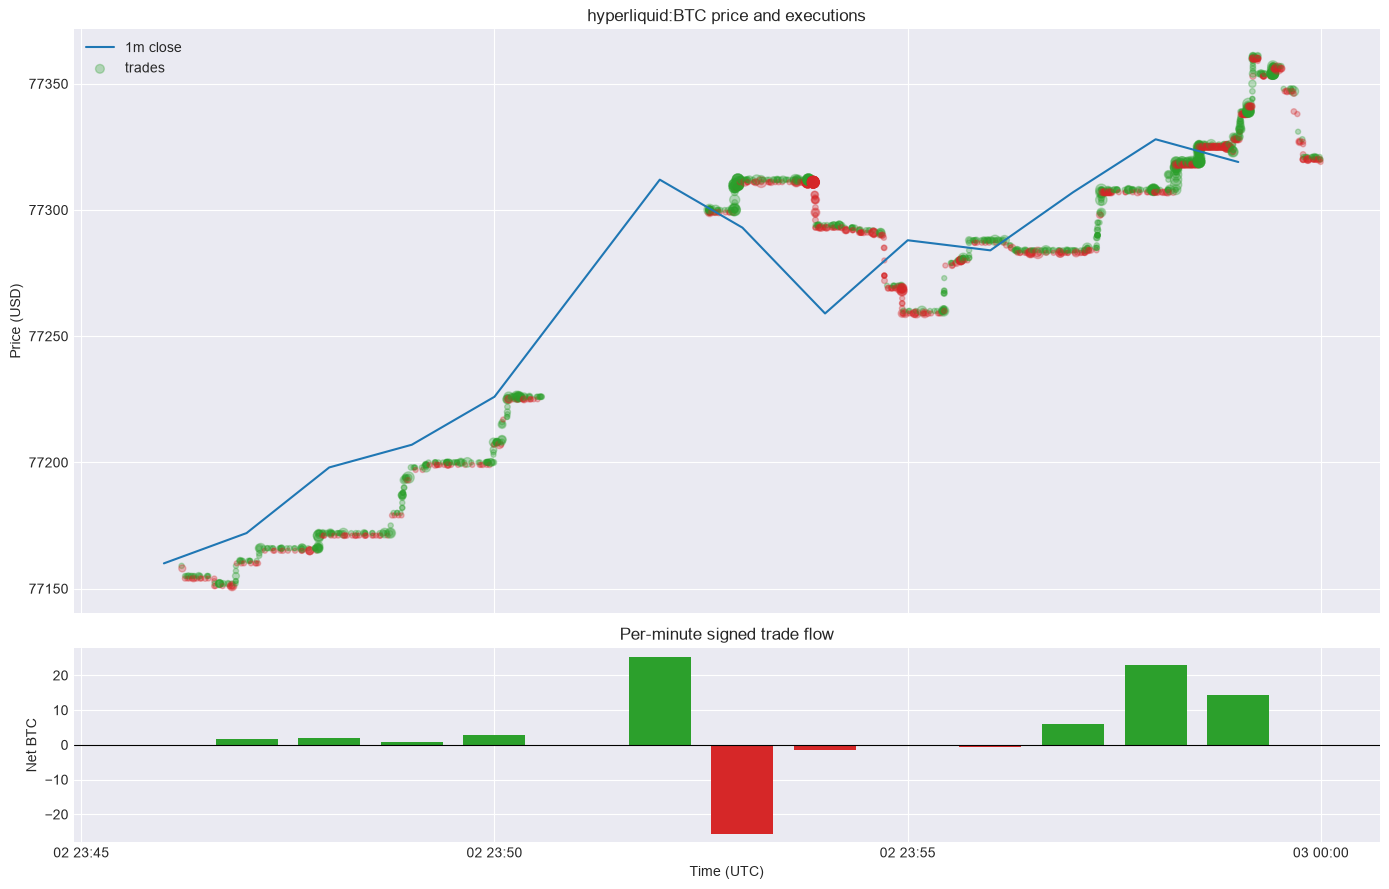

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

if not bars_df.empty:
    axes[0].plot(bars_df.index, bars_df["close"], color="#1f77b4", linewidth=1.5, label="1m close")

if trades_df.empty:
    axes[0].text(0.5, 0.5, "No trades in the selected public window", ha="center", va="center", transform=axes[0].transAxes)
else:
    scale = trades_df["quantity"].quantile(0.95)
    scale = scale if scale > 0 else 1.0
    marker_sizes = 12 + 55 * (trades_df["quantity"].clip(upper=scale) / scale) ** 0.5
    colors = trades_df["side"].map({"buy": "#2ca02c", "sell": "#d62728"}).fillna("#7f7f7f")
    axes[0].scatter(trades_df["timestamp"], trades_df["price"], s=marker_sizes, c=colors, alpha=0.3, label="trades")
    axes[0].legend(loc="upper left")

axes[0].set_title(f"{source}:{market} price and executions")
axes[0].set_ylabel("Price (USD)")

if trade_flow.empty:
    axes[1].text(0.5, 0.5, "No signed flow to aggregate", ha="center", va="center", transform=axes[1].transAxes)
else:
    colors = ["#2ca02c" if value >= 0 else "#d62728" for value in trade_flow]
    axes[1].bar(trade_flow.index, trade_flow.values, width=pd.Timedelta(seconds=45), color=colors)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Per-minute signed trade flow")
axes[1].set_ylabel("Net BTC")
axes[1].set_xlabel("Time (UTC)")

plt.tight_layout()
plt.show()
